In [10]:
# Runtime dependency check (installs only missing packages in Colab / ephemeral environments)
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "pandas": "pandas>=2.0.0",
    "numpy": "numpy>=1.24.0",
    "scipy": "scipy>=1.10.0",
    "statsmodels": "statsmodels>=0.14.0",
    "sklearn": "scikit-learn>=1.3.0",
    "matplotlib": "matplotlib>=3.7.0",
    "seaborn": "seaborn>=0.12.0",
    "GEOparse": "GEOparse>=2.0.3",
    "six": "six>=1.16.0",
    "Bio": "biopython>=1.81",
    "gseapy": "gseapy>=1.0.4",
}

missing = [pkg_spec for mod, pkg_spec in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print(f"Installing missing packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already available.")

All required packages are already available.


In [11]:
import os
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")

IN_COLAB = "google.colab" in sys.modules
GITHUB_REPO_URL = "https://github.com/disulamihisara123/pharmaco-ocd.git"

if IN_COLAB:
    # Set USE_GOOGLE_DRIVE = True if you store pharmaco-ocd in Google Drive
    USE_GOOGLE_DRIVE = False
    if USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = "/content/drive/MyDrive/pharmaco-ocd"
    else:
        PROJECT_ROOT = "/content/pharmaco-ocd"
        if not os.path.exists(os.path.join(PROJECT_ROOT, "src", "data_loader.py")):
            print(f"Cloning {GITHUB_REPO_URL} into {PROJECT_ROOT}...")
            subprocess.check_call(["git", "clone", "-q", GITHUB_REPO_URL, PROJECT_ROOT])
else:
    cwd = os.getcwd()
    PROJECT_ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebooks" else cwd

SRC_DIR = os.path.join(PROJECT_ROOT, "src")
if not os.path.exists(os.path.join(SRC_DIR, "data_loader.py")):
    raise FileNotFoundError(f"Could not find src/data_loader.py under {PROJECT_ROOT}.")

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from data_loader import (
    download_file,
    download_platform_annotation,
    get_geo_series_url,
    parse_series_matrix,
)
from preprocess import (
    check_and_apply_log2,
    clean_missing_probes,
    compute_sample_qc_metrics,
    filter_low_variance_probes,
    harmonize_cohorts,
    map_probes_to_genes,
)

DATA_RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw")
DATA_PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
DATA_META_DIR = os.path.join(PROJECT_ROOT, "data", "metadata")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "reports", "figures")

for d in [DATA_RAW_DIR, DATA_PROCESSED_DIR, DATA_META_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"Environment initialized ({'Google Colab' if IN_COLAB else 'Local Python'}).")
print(f"Project Root: {PROJECT_ROOT}")

Environment initialized (Google Colab).
Project Root: /content/pharmaco-ocd


In [12]:
COHORTS = {
    "GSE60190": {"role": "OCD Brain Cohort (DLPFC)", "gpl": "GPL6947"},
    "GSE149980": {"role": "SSRI Citalopram Response (LCLs)", "gpl": "GPL17077"},
    "GSE83386": {"role": "SSRI Fluoxetine Response (LCLs)", "gpl": "GPL17077"},
    "GSE76826": {"role": "MDD Remission Blood Cohort", "gpl": "GPL17077"},
}

gpl_paths = {
    gpl: download_platform_annotation(gpl, DATA_RAW_DIR)
    for gpl in sorted({info["gpl"] for info in COHORTS.values()})
}

raw_exprs = {}
metas = {}
summary_rows = []

for gse_id, info in COHORTS.items():
    dest = os.path.join(DATA_RAW_DIR, f"{gse_id}_series_matrix.txt.gz")
    download_file(get_geo_series_url(gse_id), dest)
    df_expr, df_meta = parse_series_matrix(dest)
    raw_exprs[gse_id] = df_expr
    metas[gse_id] = df_meta
    summary_rows.append({
        "Cohort": gse_id,
        "Role": info["role"],
        "Platform": info["gpl"],
        "Probes": df_expr.shape[0],
        "Samples": df_expr.shape[1],
        "Metadata_Cols": df_meta.shape[1],
    })

df_cohort_summary = pd.DataFrame(summary_rows)
display(df_cohort_summary)

[CACHE] Platform annotation already exists: /content/pharmaco-ocd/data/raw/GPL17077_platform.txt.gz
[CACHE] Platform annotation already exists: /content/pharmaco-ocd/data/raw/GPL6947_platform.txt.gz
[CACHE] File already exists: /content/pharmaco-ocd/data/raw/GSE60190_series_matrix.txt.gz
[CACHE] File already exists: /content/pharmaco-ocd/data/raw/GSE149980_series_matrix.txt.gz
[CACHE] File already exists: /content/pharmaco-ocd/data/raw/GSE83386_series_matrix.txt.gz
[CACHE] File already exists: /content/pharmaco-ocd/data/raw/GSE76826_series_matrix.txt.gz


,Cohort,Role,Platform,Probes,Samples,Metadata_Cols
0,GSE60190,OCD Brain Cohort (DLPFC),GPL6947,48679,133,42
1,GSE149980,SSRI Citalopram Response (LCLs),GPL17077,50739,68,29
2,GSE83386,SSRI Fluoxetine Response (LCLs),GPL17077,50737,20,32
3,GSE76826,MDD Remission Blood Cohort,GPL17077,50739,32,31


In [13]:
print("=== GSE60190: OCD vs. Detailed Clinical Diagnosis (dx) ===")
display(pd.crosstab(metas["GSE60190"]["ocd"], metas["GSE60190"]["dx"]))

print("\n=== GSE149980: SSRI Citalopram Response Status ===")
display(metas["GSE149980"]["response status"].value_counts().to_frame("Sample_Count"))

print("\n=== GSE83386: Treatment Arm vs. Clinical Outcome ===")
display(pd.crosstab(metas["GSE83386"]["treatment"], metas["GSE83386"]["clinical treatment outcome"]))

print("\n=== GSE76826: Diagnosis vs. Remission State ===")
display(pd.crosstab(metas["GSE76826"]["diagnosis"], metas["GSE76826"]["state"]))

=== GSE60190: OCD vs. Detailed Clinical Diagnosis (dx) ===


dx,Bipolar,Control,ED,MDD,OCD,Tics
ocd,,,,,,
Control,0,102,0,0,0,0
ED,8,0,3,4,0,0
OCD,4,0,0,3,6,3



=== GSE149980: SSRI Citalopram Response Status ===


,Sample_Count
response status,
responder,36
non-responder,32



=== GSE83386: Treatment Arm vs. Clinical Outcome ===


clinical treatment outcome,non-responder,responder
treatment,,
control,4,6
fluoxetine,4,6



=== GSE76826: Diagnosis vs. Remission State ===


state,Depression,Healthy,Remission
diagnosis,,,
Healthy,0,12,0
Major depressive disorder,10,0,10



--- GSE60190 ---
[QC] Data appears already log2-scaled (Min=7.37, Max=15.35, P99=12.33).

--- GSE149980 ---
[QC] Data appears already log2-scaled (Min=-15.78, Max=17.25, P99=2.42).

--- GSE83386 ---
[TRANSFORM] Data appears unlogged (Min=2.39, Max=827061.30, P99=84300.26). Applying log2...

--- GSE76826 ---
[QC] Data appears already log2-scaled (Min=-6.93, Max=11.04, P99=7.12).


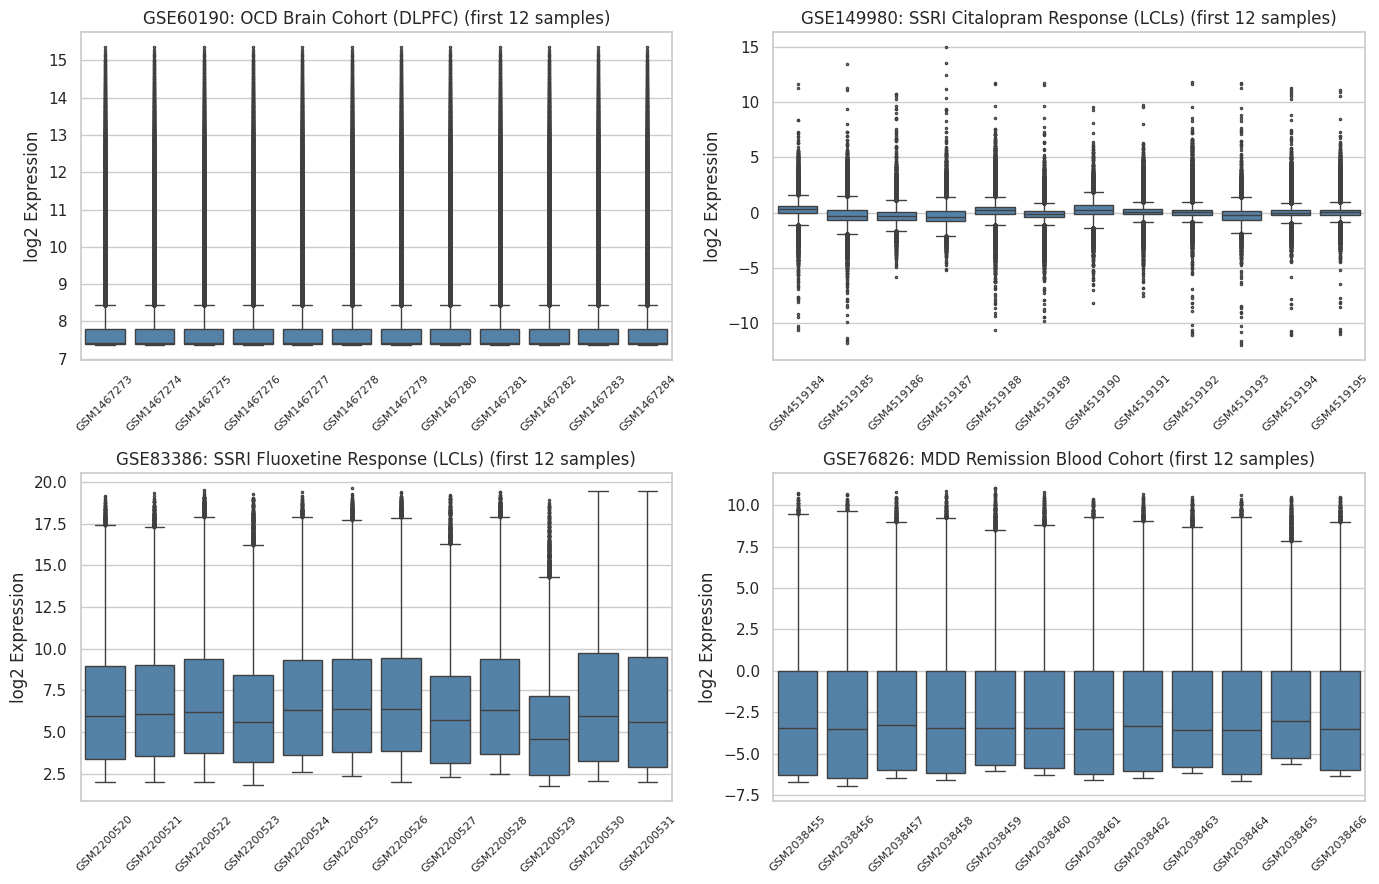

Saved figure: /content/pharmaco-ocd/reports/figures/m1_normalization_distributions.png


In [14]:
norm_exprs = {}
for gse_id, df_raw in raw_exprs.items():
    print(f"\n--- {gse_id} ---")
    df_clean = clean_missing_probes(df_raw, max_missing_rate=0.20)
    norm_exprs[gse_id] = check_and_apply_log2(df_clean)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (gse_id, df_n) in zip(axes.flat, norm_exprs.items()):
    subset = df_n.iloc[:, :min(12, df_n.shape[1])]
    sns.boxplot(data=subset, ax=ax, color="steelblue", fliersize=1.5)
    ax.set_title(f"{gse_id}: {COHORTS[gse_id]['role']} (first {subset.shape[1]} samples)")
    ax.set_ylabel("log2 Expression")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
fig_norm_path = os.path.join(FIGURES_DIR, "m1_normalization_distributions.png")
plt.savefig(fig_norm_path, dpi=150)
plt.show()
print(f"Saved figure: {fig_norm_path}")

GSE60190: 133 samples | Flagged outliers: 4 ['GSM1467319', 'GSM1467357', 'GSM1467368', 'GSM1467402']
GSE149980: 68 samples | Flagged outliers: 0 []
GSE83386: 20 samples | Flagged outliers: 0 []
GSE76826: 32 samples | Flagged outliers: 2 ['GSM2038465', 'GSM2038478']


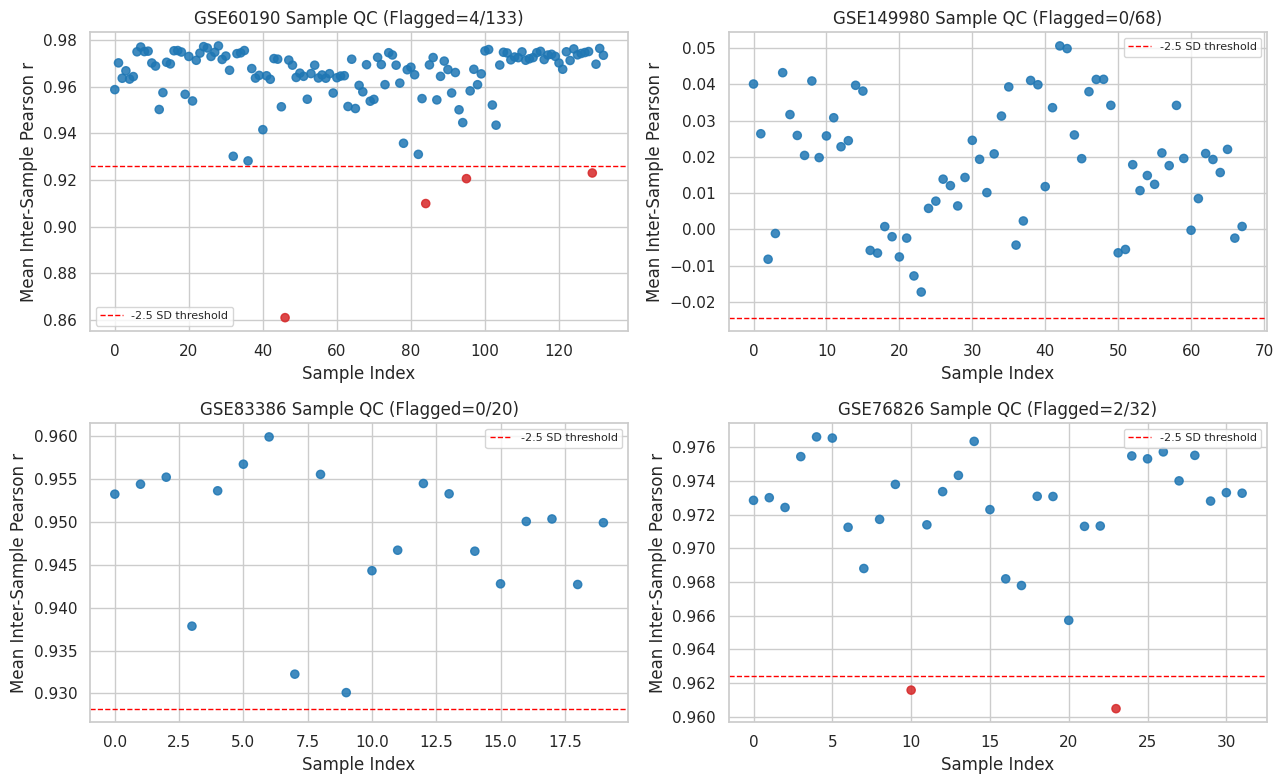

Saved figure: /content/pharmaco-ocd/reports/figures/m1_sample_qc_correlations.png


In [15]:
qc_tables = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, (gse_id, df_n) in zip(axes.flat, norm_exprs.items()):
    qc_df = compute_sample_qc_metrics(df_n, z_threshold=2.5)
    qc_tables[gse_id] = qc_df
    flagged = qc_df[qc_df["qc_flag"]]
    print(f"{gse_id}: {len(qc_df)} samples | Flagged outliers: {len(flagged)} {list(flagged.index)}")

    colors = ["#d62728" if flag else "#1f77b4" for flag in qc_df["qc_flag"]]
    ax.scatter(range(len(qc_df)), qc_df["mean_sample_corr"], c=colors, s=35, alpha=0.85)
    threshold_line = qc_df["mean_sample_corr"].mean() - 2.5 * qc_df["mean_sample_corr"].std()
    ax.axhline(threshold_line, color="red", linestyle="--", linewidth=1, label="-2.5 SD threshold")
    ax.set_title(f"{gse_id} Sample QC (Flagged={len(flagged)}/{len(qc_df)})")
    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Mean Inter-Sample Pearson r")
    ax.legend(fontsize=8)

plt.tight_layout()
fig_qc_path = os.path.join(FIGURES_DIR, "m1_sample_qc_correlations.png")
plt.savefig(fig_qc_path, dpi=150)
plt.show()
print(f"Saved figure: {fig_qc_path}")

In [16]:
gene_exprs = {}
mapping_rows = []

for gse_id, df_n in norm_exprs.items():
    gpl_id = COHORTS[gse_id]["gpl"]
    df_gene = map_probes_to_genes(df_n, gpl_paths[gpl_id])
    df_var50 = filter_low_variance_probes(df_gene, top_percentile=0.5)
    gene_exprs[gse_id] = df_gene
    mapping_rows.append({
        "Cohort": gse_id,
        "Platform": gpl_id,
        "Normalized_Probes": df_n.shape[0],
        "Unique_Genes": df_gene.shape[0],
        "Top50pct_HighVar_Genes": df_var50.shape[0],
    })

display(pd.DataFrame(mapping_rows))

[MAPPING] Mapped 36068 probes -> 25123 unique gene symbols (col='Symbol').
[VARIANCE FILTER] Reduced from 25123 to 12562 high-variance features.
[MAPPING] Mapped 46204 probes -> 32080 unique gene symbols (col='GENE_SYMBOL').
[VARIANCE FILTER] Reduced from 32080 to 16040 high-variance features.
[MAPPING] Mapped 46204 probes -> 32080 unique gene symbols (col='GENE_SYMBOL').
[VARIANCE FILTER] Reduced from 32080 to 16040 high-variance features.
[MAPPING] Mapped 46204 probes -> 32080 unique gene symbols (col='GENE_SYMBOL').
[VARIANCE FILTER] Reduced from 32080 to 16040 high-variance features.


,Cohort,Platform,Normalized_Probes,Unique_Genes,Top50pct_HighVar_Genes
0,GSE60190,GPL6947,48679,25123,12562
1,GSE149980,GPL17077,50739,32080,16040
2,GSE83386,GPL17077,50737,32080,16040
3,GSE76826,GPL17077,50739,32080,16040


[HARMONIZE] Found 17188 shared genes across 4 cohorts.
[HARMONIZE] Final harmonized feature space: 17188 genes.
[HARMONIZE] Found 17188 shared genes across 4 cohorts.
[HARMONIZE] Final harmonized feature space: 17188 genes.


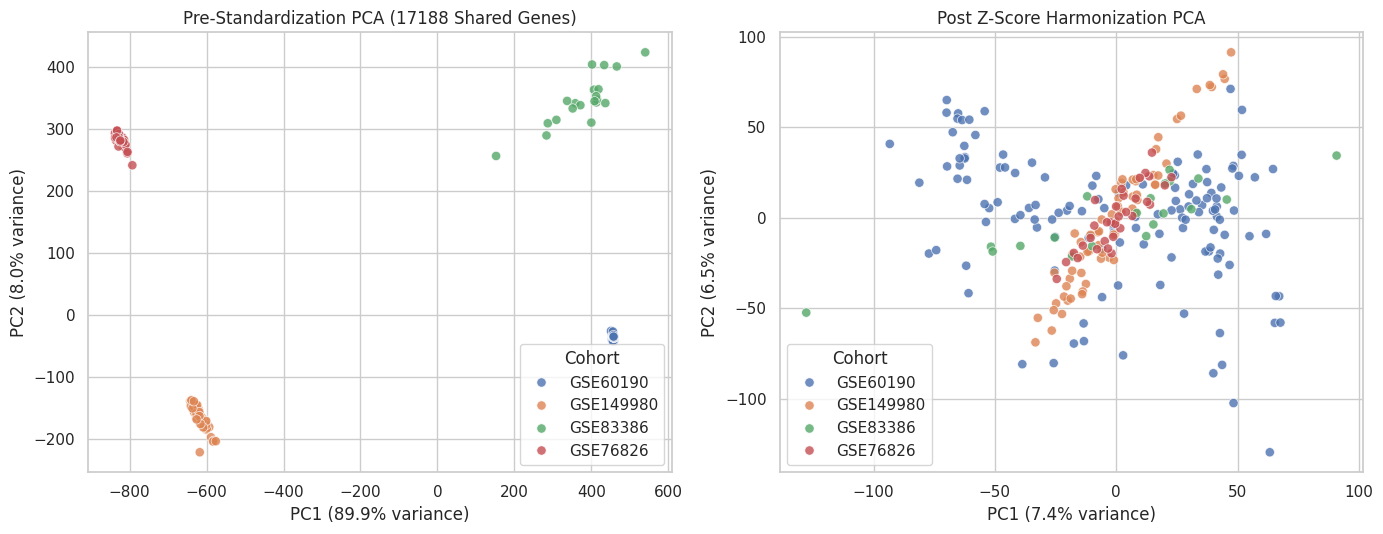

PGC/SSRI candidate genes in harmonized intersection (11/11): ['SLC1A1', 'SLC6A4', 'HTR2A', 'BDNF', 'COMT', 'DLGAP3', 'IL6', 'GRIN2B', 'HTR1A', 'TPH2', 'MAOA']
Missing candidates: []


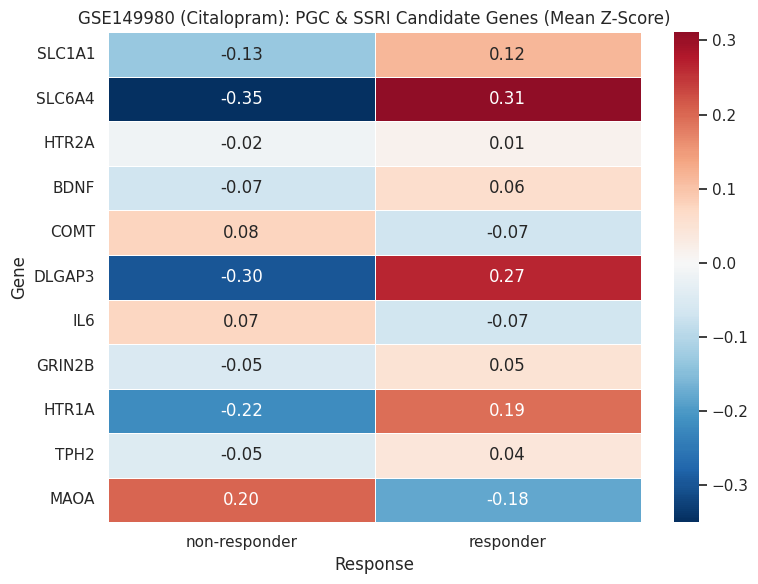

In [17]:
harmonized_raw, common_genes = harmonize_cohorts(gene_exprs, zscore=False)
harmonized_z, _ = harmonize_cohorts(gene_exprs, zscore=True)

def build_pca_df(expr_dict):
    combined = pd.concat(expr_dict.values(), axis=1)
    cohort_labels = [name for name, df in expr_dict.items() for _ in range(df.shape[1])]
    pca = PCA(n_components=2, random_state=42)
    coords = pca.fit_transform(combined.T)
    return pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "Cohort": cohort_labels}), pca.explained_variance_ratio_

df_pca_raw, var_raw = build_pca_df(harmonized_raw)
df_pca_z, var_z = build_pca_df(harmonized_z)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df_pca_raw, x="PC1", y="PC2", hue="Cohort", ax=axes[0], s=45, alpha=0.8)
axes[0].set_title(f"Pre-Standardization PCA ({len(common_genes)} Shared Genes)")
axes[0].set_xlabel(f"PC1 ({var_raw[0]*100:.1f}% variance)")
axes[0].set_ylabel(f"PC2 ({var_raw[1]*100:.1f}% variance)")

sns.scatterplot(data=df_pca_z, x="PC1", y="PC2", hue="Cohort", ax=axes[1], s=45, alpha=0.8)
axes[1].set_title("Post Z-Score Harmonization PCA")
axes[1].set_xlabel(f"PC1 ({var_z[0]*100:.1f}% variance)")
axes[1].set_ylabel(f"PC2 ({var_z[1]*100:.1f}% variance)")

plt.tight_layout()
fig_pca_path = os.path.join(FIGURES_DIR, "m1_pca_cohorts.png")
plt.savefig(fig_pca_path, dpi=150)
plt.show()

# PGC & SSRI candidate gene presence and baseline separation in GSE149980
PGC_CANDIDATES = ["SLC1A1", "SLC6A4", "HTR2A", "BDNF", "COMT", "DLGAP3", "IL6", "GRIN2B", "HTR1A", "TPH2", "MAOA"]
present_pgc = [g for g in PGC_CANDIDATES if g in common_genes]
missing_pgc = [g for g in PGC_CANDIDATES if g not in common_genes]
print(f"PGC/SSRI candidate genes in harmonized intersection ({len(present_pgc)}/{len(PGC_CANDIDATES)}): {present_pgc}")
print(f"Missing candidates: {missing_pgc}")

df_149_pgc = harmonized_z["GSE149980"].loc[present_pgc].T
df_149_pgc["Response"] = metas["GSE149980"].loc[df_149_pgc.index, "response status"]
group_means = df_149_pgc.groupby("Response").mean().T

plt.figure(figsize=(8, 6))
sns.heatmap(group_means, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("GSE149980 (Citalopram): PGC & SSRI Candidate Genes (Mean Z-Score)")
plt.tight_layout()
fig_pgc_path = os.path.join(FIGURES_DIR, "m1_candidate_genes_heatmap.png")
plt.savefig(fig_pgc_path, dpi=150)
plt.show()

In [18]:
for gse_id in COHORTS:
    gene_exprs[gse_id].to_csv(os.path.join(DATA_PROCESSED_DIR, f"{gse_id}_gene_expr.csv.gz"), compression="gzip")
    harmonized_z[gse_id].to_csv(os.path.join(DATA_PROCESSED_DIR, f"{gse_id}_harmonized_zscore.csv.gz"), compression="gzip")
    metas[gse_id].to_csv(os.path.join(DATA_META_DIR, f"{gse_id}_metadata.csv"))
    qc_tables[gse_id].to_csv(os.path.join(DATA_META_DIR, f"{gse_id}_sample_qc.csv"))

print("Exported processed matrices, metadata, and sample QC tables successfully:")
print("  Processed:", sorted(os.listdir(DATA_PROCESSED_DIR)))
print("  Metadata:", sorted(os.listdir(DATA_META_DIR)))

Exported processed matrices, metadata, and sample QC tables successfully:
  Processed: ['.gitkeep', 'GSE149980_gene_expr.csv.gz', 'GSE149980_harmonized_zscore.csv.gz', 'GSE60190_gene_expr.csv.gz', 'GSE60190_harmonized_zscore.csv.gz', 'GSE76826_gene_expr.csv.gz', 'GSE76826_harmonized_zscore.csv.gz', 'GSE83386_gene_expr.csv.gz', 'GSE83386_harmonized_zscore.csv.gz']
  Metadata: ['.gitkeep', 'GSE149980_metadata.csv', 'GSE149980_sample_qc.csv', 'GSE60190_metadata.csv', 'GSE60190_sample_qc.csv', 'GSE76826_metadata.csv', 'GSE76826_sample_qc.csv', 'GSE83386_metadata.csv', 'GSE83386_sample_qc.csv']
